In [38]:
%matplotlib inline
from matplotlib import rcParams

import os
os.environ["OMP_NUM_THREADS"] = "1"

In [39]:


# Image processing (Third-party)
from skimage import data, io

# Scientific & Data Libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

# Scikit-Learn: Datasets
from sklearn.datasets import load_digits

# Scikit-Learn: Preprocessing & Dimensionality Reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

# Scikit-Learn: Clustering
from sklearn.cluster import AgglomerativeClustering, KMeans, MiniBatchKMeans

# Scikit-Learn: Metrics
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    confusion_matrix,
    silhouette_samples,
    silhouette_score,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Introduction to clustering

Clustering is a machine learning technique used to group unlabeled datapoints in groups called *clusters*. The grouping is done such that similar items are together in the same cluster and items in different clusters are dissimilar from each-other. Typically similarity is defined using a distance measure (Euclidean, cosine, etc). Common practical applications for clustering include: market segmentation, social network analysis, search result grouping, anomaly detection etc.


Two clustering methods will be explored in this notebook:

- K-means.
- Hierarchical clustering.

More methods can be found [here](https://scikit-learn.org/stable/modules/classes.html?highlight=cluster#module-sklearn.cluster).


#### Resources: 
* Clustering & K-means (fr): https://www.youtube.com/watch?v=FTtzd31IAOw (up to 11min)
* Clustering & K-means (en): https://www.youtube.com/watch?v=QXOkPvFM6NU  (up to 7min46)
* K-means algorithm : https://stanford.edu/~cpiech/cs221/handouts/kmeans.html

* Hierarchical clustering example with scikit-learn : https://stackabuse.com/hierarchical-clustering-with-python-and-scikit-learn/ (example on how to do hierarchical clustering with scikit-learn)
* Scikit doc for hierarchical clustering : https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering

We will not use the elbow method presented in the videos as it is flawed. Instead you will learn the silhouette plots and scores to decide the number of clusters.

### Subject comprehension 

To check your understanding, before moving further, answer the questions in your own words in the space below.

1. What is clustering?
2. What are the main steps in the standard process of clustering?
3. What is the Silhouette coefficient?
4. What are the two types of evaluation for a clustering algorithm and what is the difference between them?

*Answer here*

* Clustering is an unsupervised learning technique that groups data based on similarities.
* the main steps in standard clustering :
  1. problem definition & data understanding.
  2. data processing & feature scaling.
  3. feature selection.
  4. model selection & training.
  5. hyperparameters tuning.
  6. evaluation & interpretation.
* The Silhouette coefficient measures how well an individual data point fits into its assigned cluster compared to other clusters.
* the two types of evaluation are internal evaluation and external evaluation:
  1. internal evaluation : Evaluates the quality of clusters using only the data itself and the resulting cluster structure, without any outside reference.
  2. external evaluation : Evaluates the clusters against a known ground truth or benchmark labels that were not used during training.

### Data acquisition

Load the data about the countries statistics ( *Country-data.csv* ) file into a pandas dataframe. Make the necessary imports.

In [40]:
# code here
df = pd.read_csv("Data_Country-data.csv")
df

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
...,...,...,...,...,...,...,...,...,...,...
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310


Print a summary of the data as well as the first 5 rows.

In [41]:
# code here
print("\n*** INFO ***\n")
print(df.info())
print("\n*** DESCRIPTION ***\n")
print(df.describe())
print("\n*** HEAD ***\n")
print(df.head(5))


*** INFO ***

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB
None

*** DESCRIPTION ***

       child_mort     exports      health     imports         income   inflation  life_expec   total_fer           gdpp
count  167.000000  167.000000  167.000000  167.000000     167.000000  167.000000  167.000000  167.000000     167.000000
mean    38.270060   41.108976    6.815689   46.890215   17

### Preprocessing

To facilitate the computation of distances, keep only the numerical features in the dataset.

- Remove all non-numerical features, as well as the features related to the date.
- Make sure there are no missing values - if they exist, remove them.
- Normalize the new dataset (transform the data for multiple features to the same scale).
- Save the result in a dataframe *df_norm*

In [42]:
# code here


countries = df["country"]

# Numerical features only (drops 'country')
df_num = df.select_dtypes(include="number")


# Normalize 
df_norm = pd.DataFrame(StandardScaler().fit_transform(df_num),
                       columns=df_num.columns,
                       index=df_num.index)

df_norm.describe().round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,-0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.89,-1.50,-1.83,-1.94,-0.86,-1.14,-4.34,-1.19,-0.70
25%,-0.75,-0.63,-0.69,-0.69,-0.72,-0.57,-0.59,-0.76,-0.64
50%,-0.47,-0.22,-0.18,-0.15,-0.37,-0.23,0.29,-0.36,-0.45
75%,0.59,0.37,0.65,0.49,0.29,0.28,0.70,0.62,0.06
max,4.22,5.81,4.05,5.27,5.61,9.13,1.38,3.01,5.04


Plot histograms of features

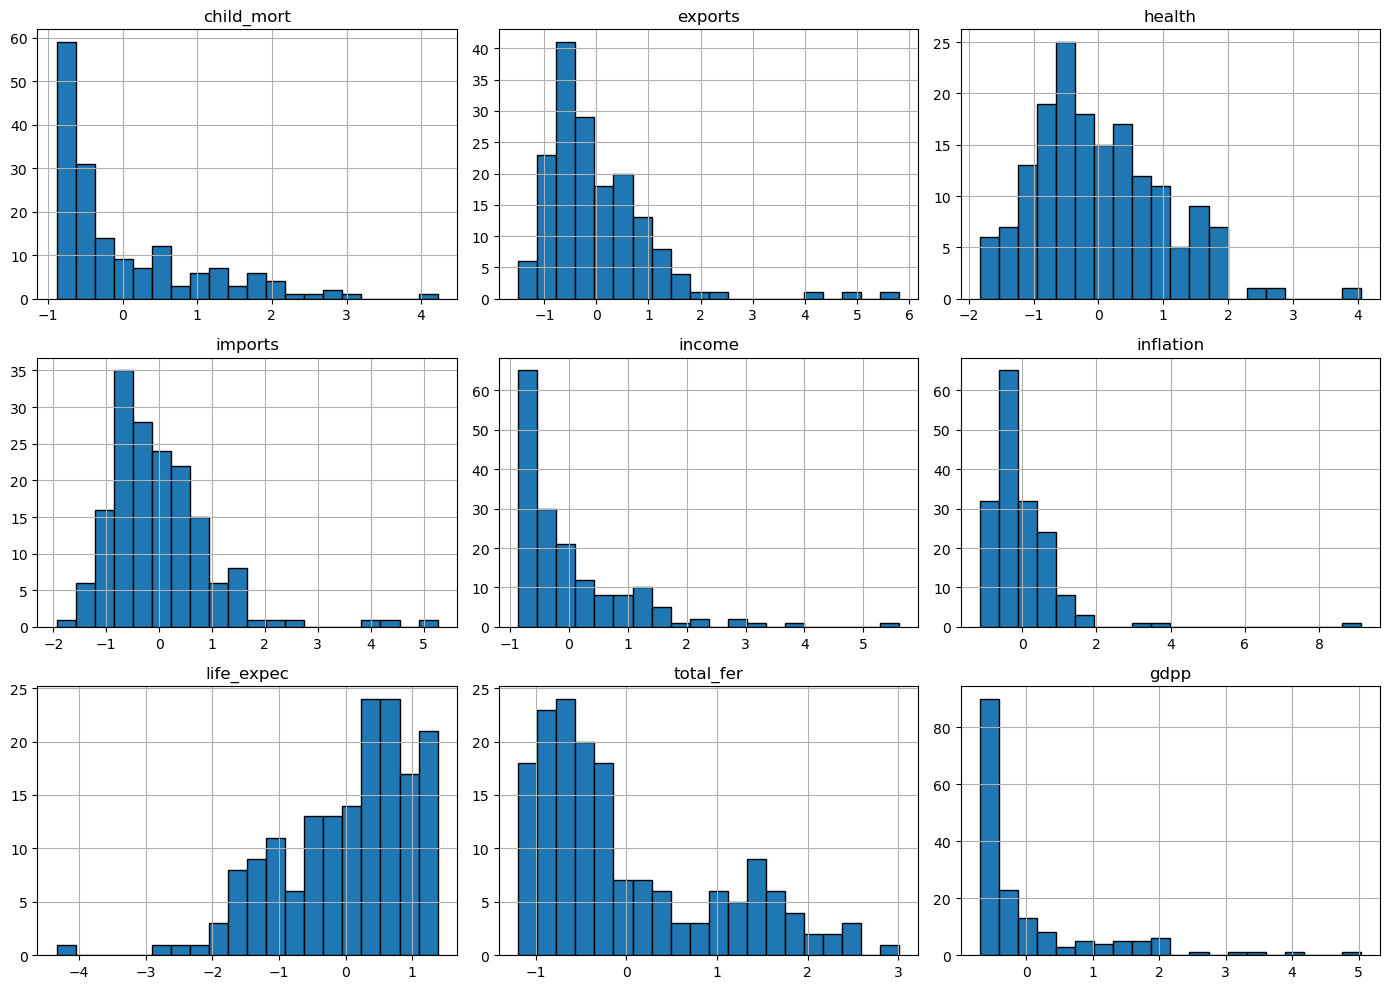

In [43]:
# code here
df_norm.hist(bins=20, figsize=(14, 10), edgecolor="black")
plt.tight_layout()
plt.show()

## KMeans


Let's warm up with the well known algorithm named KMeans!

Centroid-based clustering organizes the data into non-hierarchical clusters, contrarily to hierarchical clustering. KMeans is the most widely-used centroid-based clustering algorithm. Centroid-based algorithms are efficient but sensitive to initial conditions and outliers. 


To better understand the way the algorithm works, you can look at the following resources :
* Clustering & K-means (fr): https://www.youtube.com/watch?v=FTtzd31IAOw (up to 11min)
* Clustering & K-means (en): https://www.youtube.com/watch?v=QXOkPvFM6NU  (up to 7min46)
* https://stanford.edu/~cpiech/cs221/handouts/kmeans.html


Then answer the below questions (in your own words):
1. What is a centroid?
2. How can you compute a centroid?
3. Are you supposed to know in advance the number of clusters in order to use the KMeans algorithm?

*Answer here*

1. **Centroïde** : le centre d'un cluster, c'est-à-dire le point moyen de tous les points qui lui appartiennent. Il n'est pas forcément un point réel du dataset.
2. **Calcul** : on prend la moyenne, feature par feature, de tous les points du cluster. Pour un cluster de n points, le centroïde est (1/n) × la somme des vecteurs.
3. **Nombre de clusters** : oui, KMeans exige de fixer k à l'avance (paramètre `n_clusters`). On l'estime ensuite avec la méthode du coude (inertie) ou le score de silhouette.

#### Make the necessary imports from scikit learn in order to perform KMeans clustering

In [44]:
# code here


#### Exploring KMeans with sklearn

The goal of this step is to become familiar with the sklearn clustering package and the silhouette analysis concepts.

Start by peforming a clustering of the data in *df_norm* into 5 clusters.

In [45]:
# code here

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

kmeans.fit(df_norm)


,n_clusters,5
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


Print the centroids obtained

In [46]:
# code here
print(kmeans.cluster_centers_)

# Version plus lisible, avec les noms de colonnes
pd.DataFrame(kmeans.cluster_centers_, columns=df_norm.columns).round(2)

[[-4.14240255e-01 -4.86342568e-03 -2.36120919e-01  2.60358285e-02
  -2.25991567e-01 -1.54639981e-02  2.76216288e-01 -4.44140566e-01
  -3.49263153e-01]
 [ 1.30629603e+00 -4.18848834e-01 -1.28947379e-01 -1.32964511e-01
  -6.90624629e-01  2.05899480e-01 -1.27930022e+00  1.34238878e+00
  -6.05453328e-01]
 [-8.49003244e-01  4.93567278e+00 -8.16303241e-03  4.54805768e+00
   2.43954240e+00 -5.04206141e-01  1.22682431e+00 -1.03886271e+00
   2.44079735e+00]
 [-8.22940855e-01  1.83308008e-01  8.29894098e-01 -2.61252058e-01
   1.39837771e+00 -4.99856230e-01  1.07433094e+00 -7.68250332e-01
   1.59543611e+00]
 [ 2.28138502e+00 -5.78451631e-01 -6.37438082e-01 -1.22178479e+00
  -6.24064774e-01  9.12971806e+00 -1.13412081e+00  1.91613337e+00
  -5.81936274e-01]]


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,-0.41,-0.00,-0.24,0.03,-0.23,-0.02,0.28,-0.44,-0.35
1,1.31,-0.42,-0.13,-0.13,-0.69,0.21,-1.28,1.34,-0.61
2,-0.85,4.94,-0.01,4.55,2.44,-0.50,1.23,-1.04,2.44
3,-0.82,0.18,0.83,-0.26,1.40,-0.50,1.07,-0.77,1.60
4,2.28,-0.58,-0.64,-1.22,-0.62,9.13,-1.13,1.92,-0.58


Print the cluster labels assigned to each point

In [47]:
# code here
print(kmeans.labels_)

[1 0 0 1 0 0 0 3 3 0 3 0 0 0 0 3 0 1 0 0 0 1 0 3 0 1 1 0 1 3 0 1 1 0 0 0 1
 1 1 0 1 0 3 3 3 0 0 0 0 1 1 0 0 3 3 1 1 0 3 1 3 0 0 1 1 0 1 0 3 0 0 0 1 3
 3 3 0 3 0 0 1 1 3 0 1 0 0 1 1 0 0 2 0 1 1 0 0 1 2 1 0 0 0 0 0 0 1 0 1 0 3
 3 1 4 3 0 1 0 0 0 0 0 3 3 0 0 1 0 0 1 0 0 1 2 0 3 1 1 3 3 0 0 1 0 3 3 0 1
 0 1 1 0 0 0 0 1 0 3 3 3 0 0 0 0 0 1 1]


### **Visualization**

Let's try to visualize the created clusters. As it is easier to visualize 2-dimensional data, first run PCA on the data. Then create a scatterplot to visualize the clustered points, each coloured differently depending on the cluster they belong to.

C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


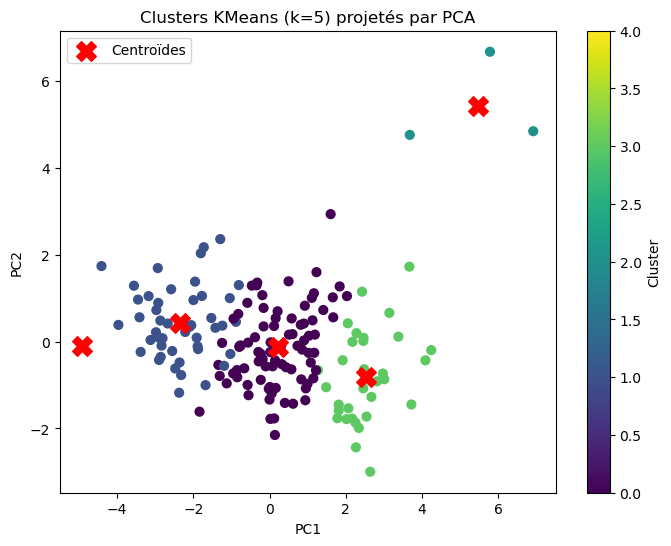

In [48]:
# code here
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_norm)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans.labels_, cmap="viridis", s=40)

# Projection des centroïdes dans l'espace PCA
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="red", marker="X", s=200, label="Centroïdes")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters KMeans (k=5) projetés par PCA")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.show()

### Evaluation

**Inertia** can be a measure of how internally coherent clusters are. It represents the within-cluster sum-of-squares.

Read more about it here:
https://scikit-learn.org/stable/modules/clustering.html#k-means 

Print the inertia obtained after the clustering.

In [49]:
# code here
print(kmeans.inertia_)

620.163371288842


**The silhouette score**

Make the necessary imports from scikit learn and compute the silhoutte score.

Read what this score represents and how it is computed here: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html and here https://scikit-learn.org/stable/modules/clustering.html#silhouette-coefficient

In [50]:
# code here

print(silhouette_score(df_norm, kmeans.labels_))

0.2992594995920442


You can read more about other clustering evaluation methods here: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

#### Finding the number of clusters

In the following article you will find [methods](https://en.wikipedia.org/wiki/Determining_the_number_of_clusters_in_a_data_set) for determining the optimal number of clusters.

The first step for using this algorithm is to use the silhouette analysis technique for obtaining the number of clusters.

(another method you can try is the [elbow method](https://en.wikipedia.org/wiki/Elbow_method_(clustering)) but this is not very reliable)

- Use the silhouette analysis to find an optimal number of clusters

<u><i>Hint:</u></i> Feel free to use the `n_jobs` hyperparameter to speed up your computation

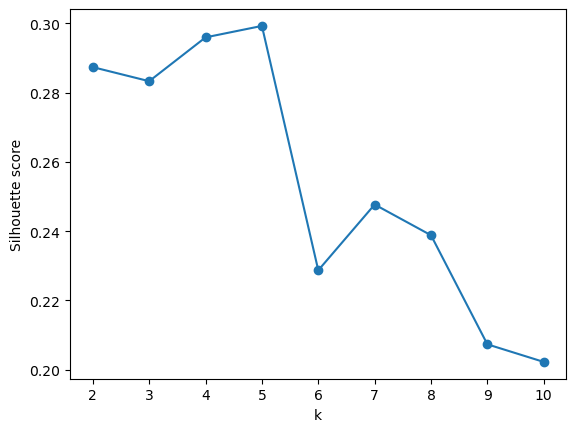

Meilleur k : 5


In [51]:
# code here


range_k = range(2, 11)
scores = []
for k in range_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(df_norm)
    scores.append(silhouette_score(df_norm, km.labels_))

plt.plot(range_k, scores, marker="o")
plt.xlabel("k"); plt.ylabel("Silhouette score"); plt.show()

best_k = list(range_k)[int(np.argmax(scores))]
print("Meilleur k :", best_k)

#### Preprocessing and model testing

Try different preprocessing methods of the data (StandardScaler, MinMaxScaler, ...) (and if you want, different clustering models (KMeans, SpectralClustering,...), and plot again PCA and TSNE to pick the combination that gives a better silhouette score, plot and separation of the clusters on the plots :

     scaler          model  silhouette
0  Standard         KMeans    0.299259
4    Robust         KMeans    0.287386
5    Robust  Agglomerative    0.270849
2    MinMax         KMeans    0.244945
3    MinMax  Agglomerative    0.228583
1  Standard  Agglomerative    0.219330


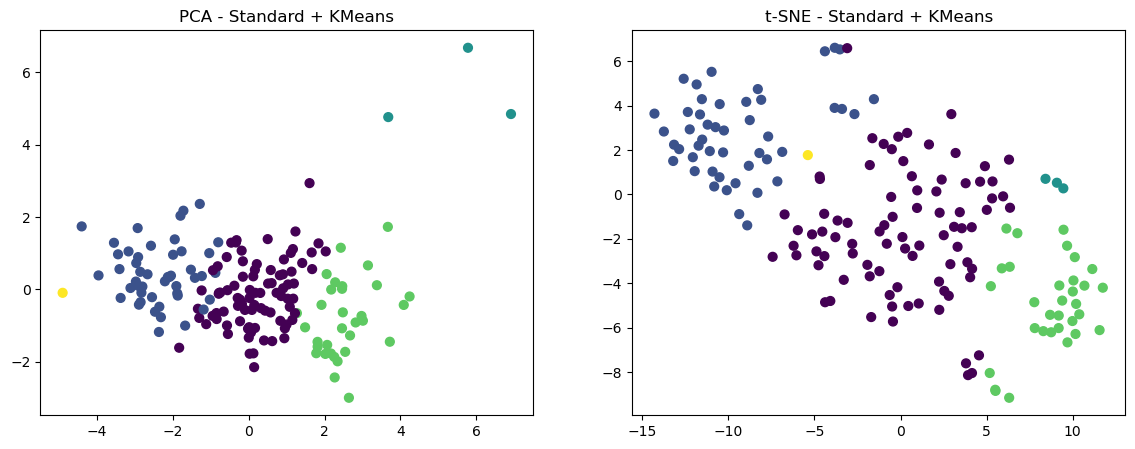

In [52]:
# code here


scalers = {"Standard": StandardScaler, "MinMax": MinMaxScaler, "Robust": RobustScaler}
models = {
    "KMeans": lambda: KMeans(n_clusters=best_k, random_state=42, n_init=10),
    "Agglomerative": lambda: AgglomerativeClustering(n_clusters=best_k),
}

results = []
for s_name, S in scalers.items():
    X = S().fit_transform(df_num)
    for m_name, M in models.items():
        labels = M().fit_predict(X)
        results.append((s_name, m_name, silhouette_score(X, labels)))

res = pd.DataFrame(results, columns=["scaler", "model", "silhouette"]).sort_values("silhouette", ascending=False)
print(res)

# Plots PCA + t-SNE pour la meilleure combinaison
best = res.iloc[0]
X = scalers[best.scaler]().fit_transform(df_num)
labels = models[best.model]().fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, proj) in zip(axes, {"PCA": PCA(2), "t-SNE": TSNE(2, random_state=42)}.items()):
    Z = proj.fit_transform(X)
    ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="viridis", s=40)
    ax.set_title(f"{name} - {best.scaler} + {best.model}")
plt.show()

What is the optimal number of clusters that you obtained?

*Answer here*
Le nombre optimal de clusters est de **k = 5**, car c'est la valeur qui maximise le score de silhouette (... avec le scaler ... et le modèle ...). Les clusters sont aussi bien séparés visuellement sur les projections PCA et t-SNE.

## Hierarchical Clustering

Let's try to apply now a different method on the same data. You can find more explanations on hierarchical clustering in the following links :
 * https://www.youtube.com/watch?v=QXOkPvFM6NU&t=1s (from minute 11:34 onwards)
 * https://stackabuse.com/hierarchical-clustering-with-python-and-scikit-learn/ (example on how to do hierarchical clustering with scikit-learn)
 * https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering

Make the necessary imports from scikit learn to perform hierarchical clustering. 

Start by plotting the dendrogram and deciding the number of clusters. Then apply hierarchical clustering.

You might find this useful: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html for creating the dendrogram.

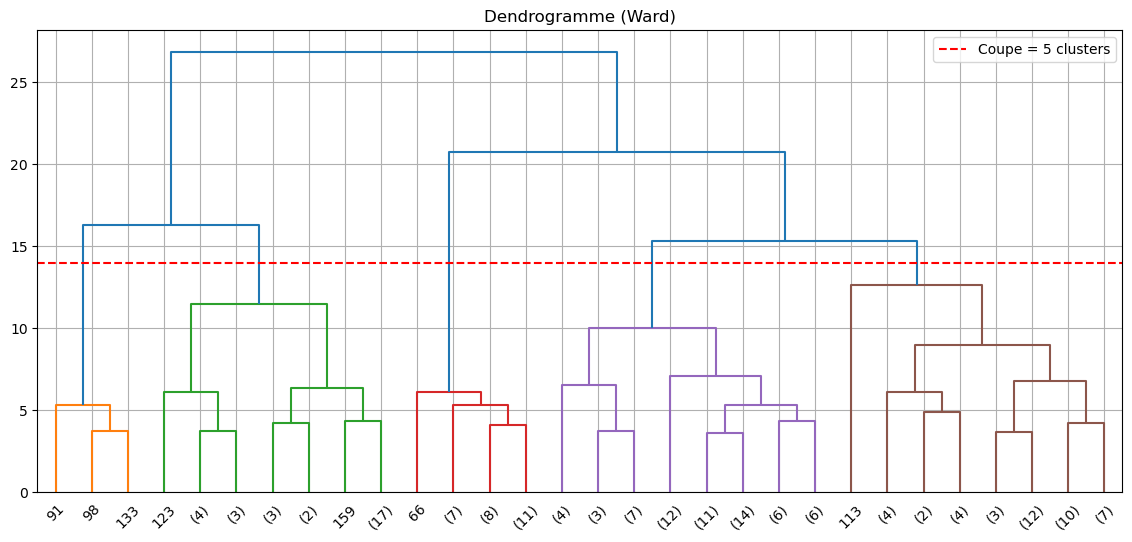

In [53]:
Z = linkage(df_norm, method="ward")

n_hier = 5

# hauteur de la ligne de coupe pour obtenir n_hier groupes
seuil = (Z[-n_hier, 2] + Z[-(n_hier - 1), 2]) / 2

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=seuil)
plt.axhline(seuil, color="red", linestyle="--", label=f"Coupe = {n_hier} clusters")
plt.title("Dendrogramme (Ward)")
plt.legend()
plt.grid()
plt.show()

hier = AgglomerativeClustering(n_clusters=n_hier, linkage="ward")
hier_labels = hier.fit_predict(df_norm)


In [54]:
print(hier_labels)

[2 4 0 0 4 0 4 1 1 4 4 1 0 4 4 1 4 2 4 0 4 4 0 1 4 2 2 4 2 1 4 2 2 0 0 0 2
 2 0 4 2 4 4 4 1 0 0 0 4 0 0 4 4 1 1 0 2 4 1 0 1 4 0 2 2 4 2 4 1 0 0 0 0 1
 1 1 4 1 4 0 2 4 1 4 0 4 4 4 4 1 4 3 4 2 2 4 4 2 3 0 4 4 4 0 4 4 2 0 4 0 1
 1 2 0 1 1 0 4 4 0 0 4 1 1 4 0 2 4 1 2 4 4 2 3 4 4 4 4 4 1 0 4 0 4 1 1 0 2
 4 0 2 4 4 0 0 2 4 1 1 1 0 0 4 0 4 0 2]


How many clusters did you find?

*Answer here*


Compare the kmeans labels with the labels obtained by the hierarchical clustering.

In [55]:
# code here



km_labels = KMeans(n_clusters=n_hier, random_state=42, n_init=10).fit_predict(df_norm)
print(pd.crosstab(km_labels, hier_labels, rownames=["KMeans"], colnames=["Hiérarchique"]))
print("Adjusted Rand Index :", adjusted_rand_score(km_labels, hier_labels))

Hiérarchique   0   1   2  3   4
KMeans                         
0             29   4   0  0  51
1             13   0  27  0   7
2              0   0   0  3   0
3              0  27   0  0   5
4              1   0   0  0   0
Adjusted Rand Index : 0.3824610345508129


### Application: clustering images

Theses techniques can be use to reduce the number of colours in a picture

- find a picture you want to reduce the number of colours.
- use `skimages` and `sklearn` to reduce the number of colours in this picture
- from your picture create two pictures with 16 colours what do you notice?

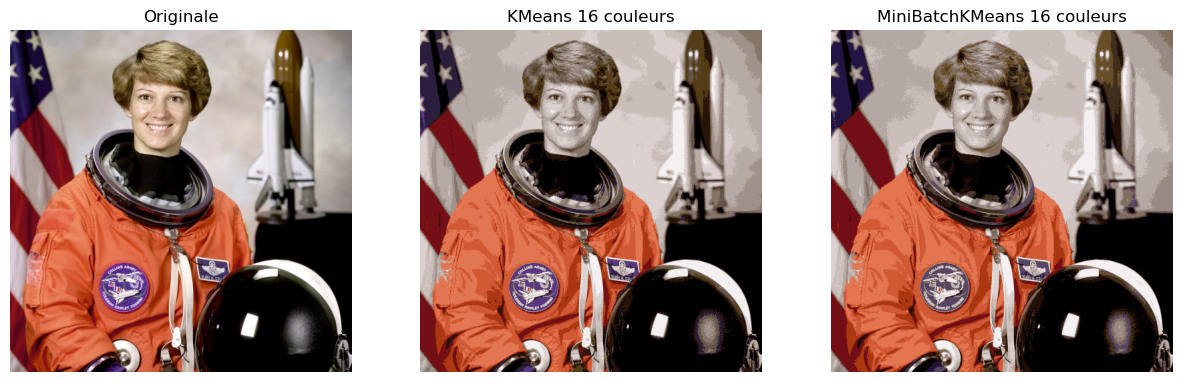

In [56]:
# install skimage
# !pip install scikit-image
#Code here


img = data.astronaut() / 255         
h, w, d = img.shape
pixels = img.reshape(-1, d)

km = KMeans(n_clusters=16, random_state=42, n_init=4).fit(pixels)
img_km = km.cluster_centers_[km.labels_].reshape(h, w, d)

mbk = MiniBatchKMeans(n_clusters=16, random_state=42, n_init=3).fit(pixels)
img_mbk = mbk.cluster_centers_[mbk.labels_].reshape(h, w, d)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axes, [img, img_km, img_mbk], ["Originale", "KMeans 16 couleurs", "MiniBatchKMeans 16 couleurs"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.show()

Now let's try to apply KMeans clustering on the simple digits data that can be loaded from sklearn (https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)

The goal is to use KMeans to try to identify similar digits without using the original label information.

Start by loading the digits and then finding the KMeans clusters. The digits data consists of 1,797 samples with 64 features, where each of the 64 features is the brightness of one pixel in an 8×8 image.

In [ ]:
# code here


digits = load_digits()
km_d = KMeans(n_clusters=10, random_state=42, n_init=10).fit(digits.data)

The cluster centroids themselves are 64-dimensional points, and can thus be interpreted as the "typical" digit within the cluster. Plot each cluster center. Hint: use *imshow*

In [ ]:
# code here
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for ax, c in zip(axes.flat, km_d.cluster_centers_):
    ax.imshow(c.reshape(8, 8), cmap="binary")
    ax.axis("off")
plt.show()

For each of the data points we also have access to their real labels (using *digits.target*). This means we can verify if the clustering algorithm split the data in such a way as to predict the original classes. 

Note that the labels of the discovered clusters may not directly match the initial labels in the dataset (they could be permuted). Write code to match each learned cluster label with the true labels of the data found in them.

In [ ]:
# code here
def match_labels(clusters, target):
    mapped = np.zeros_like(clusters)
    for i in np.unique(clusters):
        mask = clusters == i
        mapped[mask] = np.bincount(target[mask]).argmax()  # label le plus fréquent
    return mapped

pred = match_labels(km_d.labels_, digits.target)

Now compute the accuracy score between the true labels from the data and the predicted ones.

In [ ]:
# code here

print(accuracy_score(digits.target, pred))

Plot the confusion matrix between the predicted labels and the actual labels. Which were the digits that were most often confused with other digits?

In [ ]:
# code here


cm = confusion_matrix(digits.target, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predit"); plt.ylabel("Reel"); plt.show()

What if instead of keeping the original 64 features, we perform a projection into 2 dimensions?
Use the t-distributed stochastic neighbor embedding (t-SNE) algorithm to pre-process the data before performing KMeans. t-SNE is a nonlinear embedding algorithm that is particularly adept at preserving points within clusters.

Compute the new accuracy.

In [ ]:
# code here

X_tsne = TSNE(n_components=2, init="pca", random_state=42).fit_transform(digits.data)
km_t = KMeans(n_clusters=10, random_state=42, n_init=10).fit(X_tsne)

pred_t = match_labels(km_t.labels_, digits.target)
print(accuracy_score(digits.target, pred_t))